Seed: 2226785795


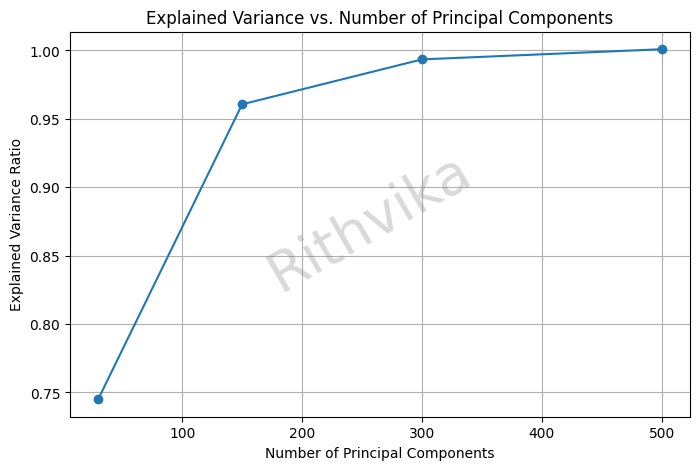

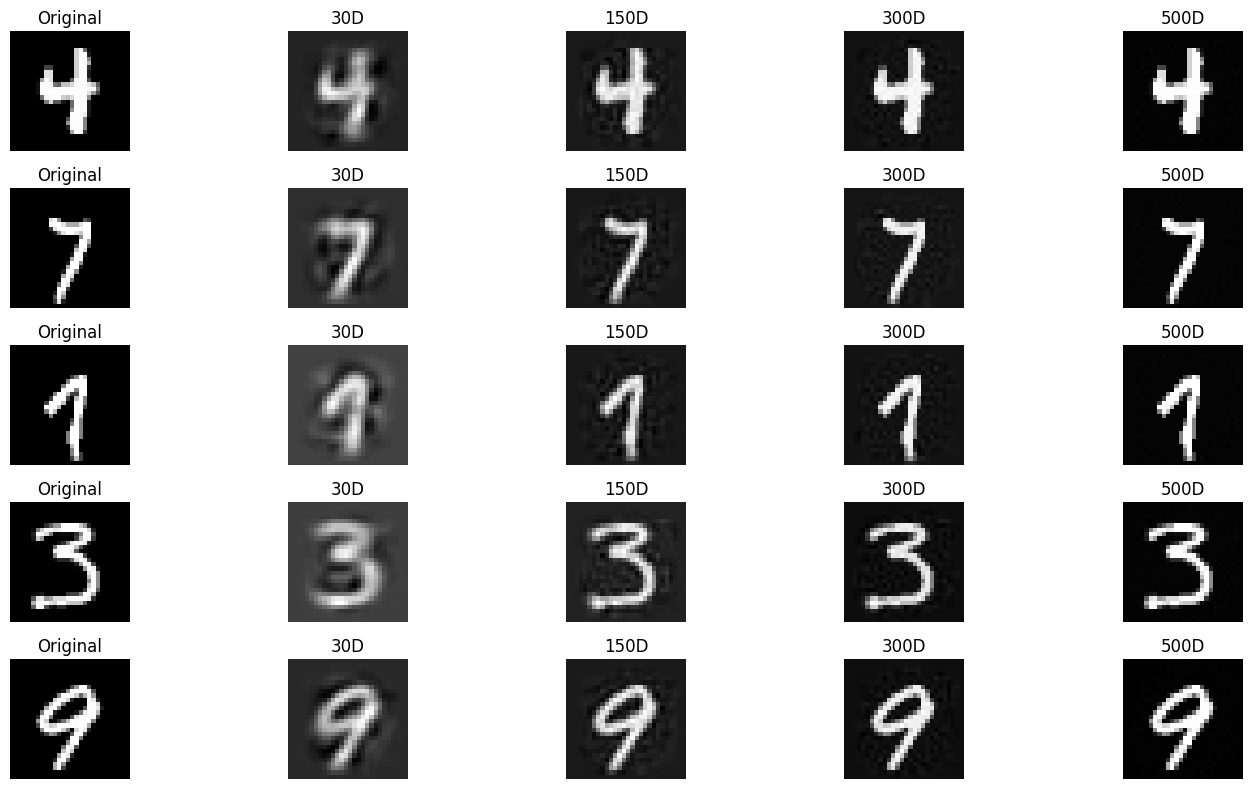

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
import hashlib
import random
from pca import CustomPCA

# -----------------------------
# Dterministic seed based on username
# -----------------------------
username = "konda.rithvika"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed:", seed)

random.seed(seed)
np.random.seed(seed)

# -----------------------------
# Load MNIST from sklearn and create balanced subset
# -----------------------------
def load_mnist_balanced_subset(seed):
    """
    Load a balanced subset of the MNIST dataset.

    This function fetches the MNIST dataset and creates a balanced subset 
    with an equal number of samples (max_per_class) from each digit class (0–9). 
    The subset is selected in a deterministic manner using the provided seed.
    """
    mnist = fetch_openml('mnist_784', version=1, as_frame=False)
    X = mnist['data']
    y = mnist['target'].astype(int)

    digit_counts = {i: 0 for i in range(10)}
    max_per_class = 100
    total_samples = 1000

    X_balanced = []
    y_balanced = []

    indices = np.arange(len(X))
    rng = np.random.default_rng(seed)
    rng.shuffle(indices)

    for idx in indices:
        label = y[idx]
        if digit_counts[label] < max_per_class:
            X_balanced.append(X[idx])
            y_balanced.append(label)
            digit_counts[label] += 1
        if sum(digit_counts.values()) == total_samples:
            break

    return np.array(X_balanced), np.array(y_balanced)



# -----------------------------
# Run PCA on different dimensions
# -----------------------------
X, y = load_mnist_balanced_subset(seed)

dimensions = [ 500, 300, 150, 30]
explained_variances = []
pca_models = {}

for dim in dimensions:
    pca = CustomPCA(n_components=dim)
    pca.fit(X)
    X_proj = pca.transform(X)
    explained_ratio = np.sum(pca.explained_variance) / np.sum(np.var(X, axis=0))
    explained_variances.append(explained_ratio)
    pca_models[dim] = (pca, X_proj)

# -----------------------------
# Plot explained variance vs components
# -----------------------------
plt.figure(figsize=(8, 5))
plt.plot(dimensions, explained_variances, marker='o', linestyle='-')
plt.title("Explained Variance vs. Number of Principal Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.grid(True)
plt.text(0.5, 0.5, 'Rithvika',
         transform=plt.gcf().transFigure,
         fontsize=40, color='gray', alpha=0.3,
         ha='center', va='center', rotation=30)
plt.show()

# -----------------------------
# Plot original and reconstructed images
# -----------------------------
def plot_reconstructions(X_original, pca_models, indices):
    
    """
    Plot original and PCA-reconstructed images.

    For a given set of sample indices, display the original MNIST images 
    alongside their reconstructions using different PCA dimensionalities.
    """
    fig, axes = plt.subplots(len(indices), len(pca_models) + 1, figsize=(15, 8))

    for i, idx in enumerate(indices):
        axes[i, 0].imshow(X_original[idx].reshape(28, 28), cmap='gray')
        axes[i, 0].set_title("Original")
        axes[i, 0].axis('off')

        for j, dim in enumerate(sorted(pca_models.keys())):
            pca, X_proj = pca_models[dim]
            recon = pca.inverse_transform(X_proj[idx])
            axes[i, j + 1].imshow(recon.reshape(28, 28), cmap='gray')
            axes[i, j + 1].set_title(f"{dim}D")
            axes[i, j + 1].axis('off')

    plt.tight_layout()
    plt.show()

# Pick 5 deterministic samples
sample_indices = np.random.choice(len(X), 5, replace=False)
plot_reconstructions(X, pca_models, sample_indices)


## Observations on PCA Performance on MNIST Data

#### 1. Explained Variance vs. Number of Principal Components
- The plot says :
- With **30 components**, only about **74%** of the total variance is retained.
- At **150 components**, over **95%** of the variance is captured.
- **300 components** push this ratio closer to **100%**, showing that most of the important data structure is preserved.
- **500 components** add only marginal improvement, showing **diminishing returns**.

### Key Insight:
> Most of the important variance in MNIST images can be captured by fewer than **300 components**, offering significant dimensionality reduction with minimal information loss.

---

#### 2. Image Reconstruction Quality

The reconstructed images (at 30D, 150D, 300D, and 500D) were compared against the original images:

#####  30D:
- Digits are still **recognizable**, but very **blurry**.
- Fine details such as edges and stroke sharpness are **lost**.

#####  150D:
- Much **clearer reconstructions**.
- Digit shapes are well-preserved and **easily identifiable**.

#####  300D:
- Further **improvement in detail and sharpness**.
- Images are nearly **indistinguishable from the original**.

#####  500D:
- Visually **identical to original**.
- However, there is **very little improvement over 300D**, indicating possible **redundancy**.

##### Key Insight:
> Even a **small number of components (e.g., 150)** can provide **high-quality reconstructions**.  
> **300D is a sweet spot**, balancing quality and efficiency.  
> **500D may be excessive** for practical purposes.

---

### 3. Conclusion

- PCA effectively **compresses high-dimensional image data** while preserving essential features.

---
